In [1]:
import pandas as pd
from datetime import datetime
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./New/'))
file_path = cPath + '/Combined_Terminal_Label.csv'
print(file_path)
myData = pd.read_csv(file_path, parse_dates=['DateTime'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('DateTime', drop = False, inplace=True)
# print(myData.head)
print(myData.index.name)
print(myData)

/home/homayoun/Dropbox/Projects/VisualCode/Python/CAE/New/KWH_based/Combined_Terminal_Label.csv
DateTime
                               DateTime  KWH11    KW  Year     Delta     label
DateTime                                                                      
2014-07-01 00:14:00 2014-07-01 00:14:00  357.5  1430  2014  0.005000  sOffPeak
2014-07-01 00:29:00 2014-07-01 00:29:00  362.0  1448  2014 -0.012778  sOffPeak
2014-07-01 00:44:00 2014-07-01 00:44:00  350.5  1402  2014 -0.006667  sOffPeak
2014-07-01 00:59:00 2014-07-01 00:59:00  344.5  1378  2014 -0.022222  sOffPeak
2014-07-01 01:14:00 2014-07-01 01:14:00  324.5  1298  2014 -0.000556  sOffPeak
...                                 ...    ...   ...   ...       ...       ...
2024-12-31 22:59:00 2024-12-31 22:59:00  223.5   894  2024 -0.027778  wOffPeak
2024-12-31 23:14:00 2024-12-31 23:14:00  198.5   794  2024  0.013889  wOffPeak
2024-12-31 23:29:00 2024-12-31 23:29:00  211.0   844  2024  0.008889  wOffPeak
2024-12-31 23:44:00 2024-1

In [3]:
# Convert 15-minute KWH11 data to hourly usage by summing values for each day
hourlyUsage = myData.groupby(myData['DateTime'].dt.floor('h'))['KWH11'].sum().reset_index()
hourlyUsage.columns = ['Date', 'hourly_KWH']
hourlyUsage['Date'] = pd.to_datetime(hourlyUsage['Date'])
hourlyUsage.set_index('Date', inplace=True)

print(f"hourly usage data shape: {hourlyUsage.shape}")
print(hourlyUsage.head())
print(hourlyUsage.tail())

hourly usage data shape: (92065, 1)
                     hourly_KWH
Date                           
2014-07-01 00:00:00      1414.5
2014-07-01 01:00:00      1296.5
2014-07-01 02:00:00      1294.5
2014-07-01 03:00:00      1297.5
2014-07-01 04:00:00      1327.0
                     hourly_KWH
Date                           
2024-12-31 19:00:00       485.5
2024-12-31 20:00:00       490.0
2024-12-31 21:00:00       633.0
2024-12-31 22:00:00       858.0
2024-12-31 23:00:00       822.5


In [8]:
# Prepare data for regression: use 168 previous hours (7 days) to predict the next hour
# Only using hourly_KWH column from hourlyUsage

# Create features (X) and target (y)
n_hours = 168  # 7 days * 24 hours

# Extract hourly_KWH column
kwh_data = hourlyUsage['hourly_KWH'].values

# Create sequences of 168 hours to predict the next hour
X = []
y = []

for i in range(len(kwh_data) - n_hours - 24):
    X.append(kwh_data[i:i+n_hours])
    y.append(kwh_data[i+n_hours:i+n_hours+24])  # Next 24 hours' usage

X = np.array(X)
y = np.array(y)
print('X=', X[0])
print('y=', y[0])

# Split into train and test sets (80-20 split)
split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Train linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

X= [1414.5 1296.5 1294.5 1297.5 1327.  1377.5 1309.5 1209.5 1008.5 1003.5
 1080.  1123.5 1088.5  988.   957.   981.5  994.5 1027.5  958.5  949.
 1135.5 1388.5 1517.5 1515.5 1479.5 1462.5 1397.  1365.  1357.  1420.
 1304.  1196.5 1165.5 1049.  1126.5 1192.  1155.   980.   973.5 1001.
  986.5 1065.5  985.5  998.5 1039.5 1397.  1506.  1470.5 1464.5 1466.
 1409.  1337.5 1353.  1424.  1365.  1290.5 1263.5 1151.  1050.5 1065.5
 1101.   945.   961.5  984.  1011.5 1103.5 1106.  1017.  1085.5 1345.5
 1474.  1472.5 1458.  1373.5 1330.  1296.  1323.5 1364.5 1304.5 1230.5
  987.5  984.5 1017.  1021.5  980.5  862.5  865.5  875.5  885.5  911.
  933.5  915.5  910.  1165.5 1306.  1284.  1307.  1264.  1266.5 1272.
 1302.  1317.5 1065.5 1029.5  966.   959.5  967.   971.   960.5  847.
  872.5  930.   916.   922.5  879.   870.5  926.5 1175.5 1314.  1296.
 1266.  1253.5 1258.5 1266.5 1304.  1384.  1328.5 1040.  1029.5 1006.
  994.  1016.  1040.5  918.5  933.5  920.5  940.   940.5  940.   935.5
  975.5 1260

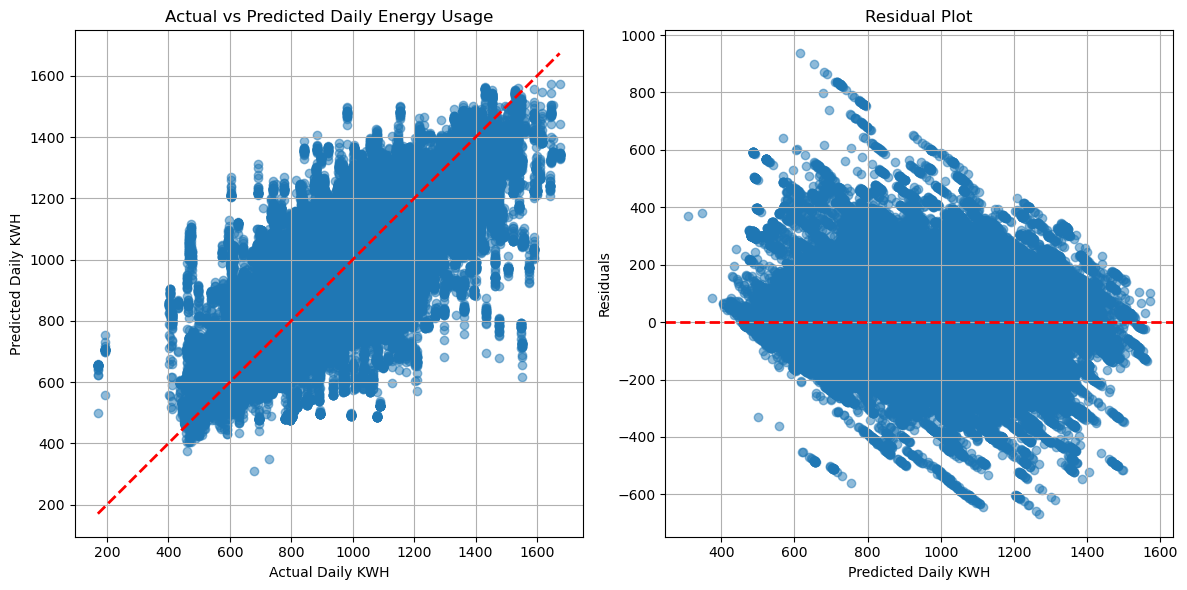

Mean Squared Error: 7887.6441
R² Score: 0.8169


In [9]:
# Plot predicted vs actual values
plt.figure(figsize=(12, 6))

# Plot actual vs predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Daily KWH')
plt.ylabel('Predicted Daily KWH')
plt.title('Actual vs Predicted Daily Energy Usage')
plt.grid(True)

# Plot residuals
plt.subplot(1, 2, 2)
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Daily KWH')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

In [10]:
""" from sklearn.svm import SVR

# Train Support Vector Regression model
svm_model = SVR(kernel='rbf', C=100, epsilon=0.1)
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

# Evaluate model
mse_svm = mean_squared_error(y_test, y_pred_svm)
r2_svm = r2_score(y_test, y_pred_svm)

print(f"SVR Mean Squared Error: {mse_svm:.4f}")
print(f"SVR R² Score: {r2_svm:.4f}") """

' from sklearn.svm import SVR\n\n# Train Support Vector Regression model\nsvm_model = SVR(kernel=\'rbf\', C=100, epsilon=0.1)\nsvm_model.fit(X_train, y_train)\n\n# Make predictions\ny_pred_svm = svm_model.predict(X_test)\n\n# Evaluate model\nmse_svm = mean_squared_error(y_test, y_pred_svm)\nr2_svm = r2_score(y_test, y_pred_svm)\n\nprint(f"SVR Mean Squared Error: {mse_svm:.4f}")\nprint(f"SVR R² Score: {r2_svm:.4f}") '

In [14]:
from sklearn.neural_network import MLPRegressor

# Train MLP regression model
mlp_model = MLPRegressor(hidden_layer_sizes=(32, 16, 8), activation='relu',
                         solver='adam', max_iter=1000, random_state=42)
mlp_model.fit(X_train, y_train)

# Make predictions
y_pred_mlp = mlp_model.predict(X_test)

# Evaluate model
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"MLP Mean Squared Error: {mse_mlp:.4f}")
print(f"MLP R² Score: {r2_mlp:.4f}")

MLP Mean Squared Error: 15585.1474
MLP R² Score: 0.6382


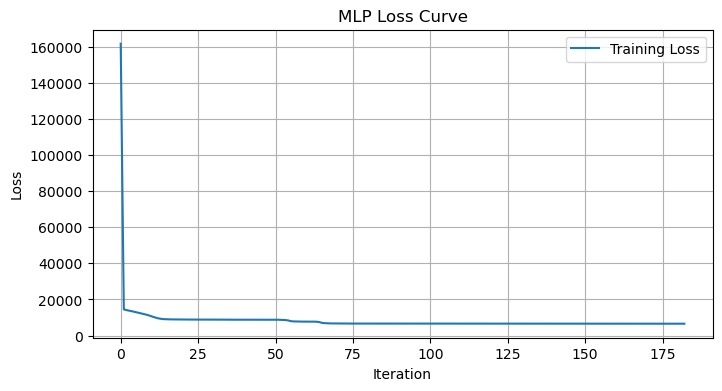

Final MLP training loss: 6563.228065
MLP Test MSE: 15585.1474


In [15]:
# Plot MLP training loss curve
plt.figure(figsize=(8, 4))
plt.plot(mlp_model.loss_curve_, label='Training Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Loss Curve')
plt.grid(True)
plt.legend()
plt.show()

print(f"Final MLP training loss: {mlp_model.loss_curve_[-1]:.6f}")
print(f"MLP Test MSE: {mse_mlp:.4f}")

In [17]:
# Get the date index for the test data (dates corresponding to y_test)
test_dates = hourlyUsage.index[n_hours + split_idx:]

# Find the split point for 2024
# Create a mask for 2024 data
mask_2024 = hourlyUsage.index >= '2024-01-01'

# Find the first index where 2024 starts
first_2024_idx = hourlyUsage.index.get_loc(hourlyUsage[mask_2024].index[0])

# Calculate the split index accounting for the n_hours offset
# We need at least n_hours samples before the test set
split_idx_2024 = first_2024_idx - n_hours

# Extract hourly_KWH column
kwh_data = hourlyUsage['hourly_KWH'].values

# Create sequences of 168 hours to predict the next hour
X = []
y = []

for i in range(len(kwh_data) - n_hours - 24):
    X.append(kwh_data[i:i+n_hours])
    y.append(kwh_data[i+n_hours:i+n_hours+24])  # Next 24 hours' usage

X = np.array(X)
y = np.array(y)

# Split: data before 2024 for training, 2024 data for testing
X_train, X_test = X[:split_idx_2024], X[split_idx_2024:]
y_train, y_test = y[:split_idx_2024], y[split_idx_2024:]

# Train all three models with the new split

# 1. Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

""" # 2. SVR
svm_model = SVR(kernel='rbf', C=100, epsilon=0.1)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
mse_svm = mean_squared_error(y_test, y_pred_svm)
r2_svm = r2_score(y_test, y_pred_svm) """

# 3. MLP
mlp_model = MLPRegressor(hidden_layer_sizes=(32, 16, 8), activation='relu',
                         solver='adam', max_iter=1000, random_state=42)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Training on data before 2024, Testing on 2024 data")
print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"\nLinear Regression - MSE: {mse:.4f}, R²: {r2:.4f}")
# print(f"SVR - MSE: {mse_svm:.4f}, R²: {r2_svm:.4f}")
print(f"MLP - MSE: {mse_mlp:.4f}, R²: {r2_mlp:.4f}")

Training on data before 2024, Testing on 2024 data
Training samples: 83113
Test samples: 8760

Linear Regression - MSE: 7273.6963, R²: 0.8285
MLP - MSE: 15165.5539, R²: 0.6425


ValueError: x and y must have same first dimension, but have shapes (8784,) and (8760, 24)

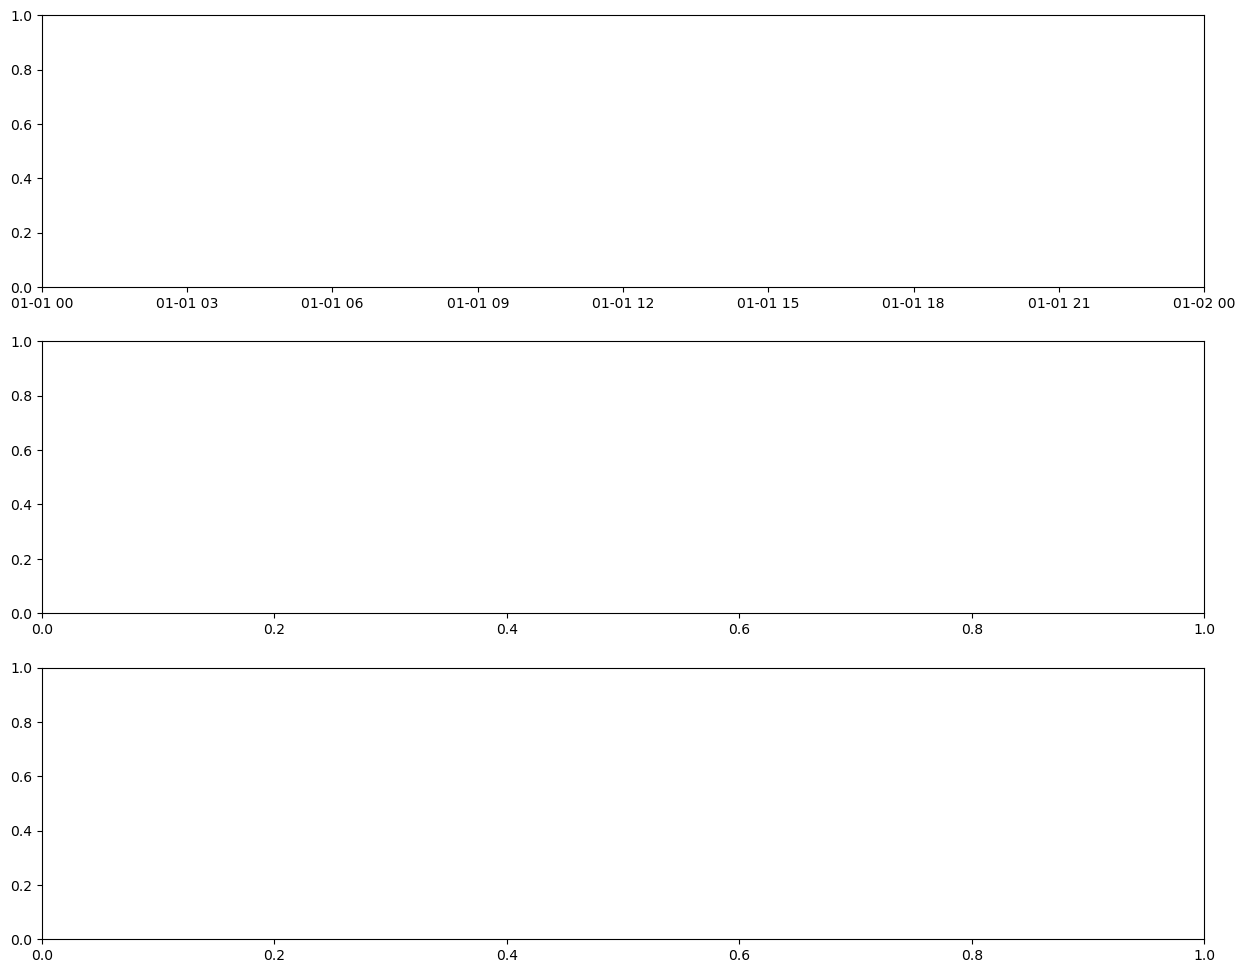

In [18]:
# Get the date index for 2024 test data
test_dates_2024 = hourlyUsage.index[n_hours + split_idx_2024:]

# Create figure with subplots for each model
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Plot Linear Regression
axes[0].plot(test_dates_2024, y_test, label='Actual', color='blue', linewidth=2)
axes[0].plot(test_dates_2024, y_pred, label='Predicted', color='red', linewidth=2, alpha=0.7)
axes[0].set_title(f'Linear Regression - 2024 Hourly Energy Usage (MSE: {mse:.2f}, R²: {r2:.4f})')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Hourly KWH')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot SVR
axes[1].plot(test_dates_2024, y_test, label='Actual', color='blue', linewidth=2)
axes[1].plot(test_dates_2024, y_pred_svm, label='Predicted', color='green', linewidth=2, alpha=0.7)
axes[1].set_title(f'Support Vector Regression - 2024 Hourly Energy Usage (MSE: {mse_svm:.2f}, R²: {r2_svm:.4f})')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Hourly KWH')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot MLP
axes[2].plot(test_dates_2024, y_test, label='Actual', color='blue', linewidth=2)
axes[2].plot(test_dates_2024, y_pred_mlp, label='Predicted', color='orange', linewidth=2, alpha=0.7)
axes[2].set_title(f'MLP Neural Network - 2024 Hourly Energy Usage (MSE: {mse_mlp:.2f}, R²: {r2_mlp:.4f})')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('Hourly KWH')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Multi-horizon forecasting: 1, 2, 3, and 5 hours ahead (using previous n_hours as features)

horizons = [1, 2, 3, 5]*24  # Convert to hours
first_2024_idx = hourlyUsage.index.get_loc(hourlyUsage[hourlyUsage.index >= '2024-01-01'].index[0])
print(first_2024_idx)
kwh_data = hourlyUsage['hourly_KWH'].values

all_results = []
predictions_by_horizon = {}

for h in horizons:
    # Build supervised dataset: X = past n_hours, y = value at t + h
    X_h, y_h = [], []
    for i in range(len(kwh_data) - n_hours - h + 1 - 24):
        X_h.append(kwh_data[i:i+n_hours])
        y_h.append(kwh_data[i+n_hours+h-1:i+n_hours+h-1+24])  # Next 24 hours' usage

    X_h = np.array(X_h)
    y_h = np.array(y_h)

    # Split so test targets start in 2024
    split_idx_h = first_2024_idx - n_hours - (h - 1)
    X_train_h, X_test_h = X_h[:split_idx_h], X_h[split_idx_h:]
    y_train_h, y_test_h = y_h[:split_idx_h], y_h[split_idx_h:]
    test_dates_h = hourlyUsage.index[n_hours + (h - 1) + split_idx_h:]

    # Linear Regression
    lr_h = LinearRegression()
    lr_h.fit(X_train_h, y_train_h)
    y_pred_lr_h = lr_h.predict(X_test_h)

    # SVR (commented out)
    # svr_h = SVR(kernel='rbf', C=100, epsilon=0.1)
    # svr_h.fit(X_train_h, y_train_h)
    # y_pred_svr_h = svr_h.predict(X_test_h)

    # MLP
    # mlp_h = MLPRegressor(hidden_layer_sizes=(32, 16, 8), activation='relu',
    #                      solver='adam', max_iter=1000, random_state=42)
    # mlp_h.fit(X_train_h, y_train_h)
    # y_pred_mlp_h = mlp_h.predict(X_test_h)

    # Metrics
    all_results.extend([
        {'Horizon_Hours': h, 'Model': 'LinearRegression', 'MSE': mean_squared_error(y_test_h, y_pred_lr_h), 'R2': r2_score(y_test_h, y_pred_lr_h)},
        # {'Horizon_Hours': h, 'Model': 'SVR', 'MSE': mean_squared_error(y_test_h, y_pred_svr_h), 'R2': r2_score(y_test_h, y_pred_svr_h)},
        # {'Horizon_Hours': h, 'Model': 'MLP', 'MSE': mean_squared_error(y_test_h, y_pred_mlp_h), 'R2': r2_score(y_test_h, y_pred_mlp_h)},
    ])

    predictions_by_horizon[h] = {
        'dates': test_dates_h,
        'y_test': y_test_h,
        'LinearRegression': y_pred_lr_h,
        # 'SVR': y_pred_svr_h,
        # 'MLP': y_pred_mlp_h
    }

# Show summary table
results_df = pd.DataFrame(all_results).sort_values(['Horizon_Hours', 'R2'], ascending=[True, False])
print(results_df)

# Plot actual vs predicted for each horizon (best model by R2)
# fig, axes = plt.subplots(len(horizons), 1, figsize=(15, 3.5 * len(horizons)), sharex=False)

# for ax, h in zip(axes, horizons):
#     d = predictions_by_horizon[h]
#     subset = results_df[results_df['Horizon_Hours'] == h].sort_values('R2', ascending=False).iloc[0]
#     best_model = subset['Model']
#     best_r2 = subset['R2']
#     best_mse = subset['MSE']

#     ax.plot(d['dates'], d['y_test'], label='Actual', color='blue', linewidth=2)
#     ax.plot(d['dates'], d[best_model], label=f'Predicted ({best_model})', linewidth=2, alpha=0.8)
#     ax.set_title(f'{h}-Hour Ahead Forecast | Best: {best_model} | MSE: {best_mse:.2f}, R²: {best_r2:.4f}')
#     ax.set_xlabel('Date')
#     ax.set_ylabel('Hourly KWH')
#     ax.grid(True, alpha=0.3)
#     ax.legend()

# plt.tight_layout()
# plt.show()

83281


In [ ]:
# Repeat multi-horizon results using only SVM (SVR)

svm_results = []
svm_predictions_by_horizon = {}

for h in horizons:
    X_h, y_h = [], []
    for i in range(len(kwh_data) - n_hours - h + 1):
        X_h.append(kwh_data[i:i+n_hours])
        y_h.append(kwh_data[i+n_hours+h-1])

    X_h = np.array(X_h)
    y_h = np.array(y_h)

    split_idx_h = first_2024_idx - n_hours - (h - 1)
    X_train_h, X_test_h = X_h[:split_idx_h], X_h[split_idx_h:]
    y_train_h, y_test_h = y_h[:split_idx_h], y_h[split_idx_h:]
    test_dates_h = hourlyUsage.index[n_hours + (h - 1) + split_idx_h:]

    svr_h = SVR(kernel='rbf', C=100, epsilon=0.1)
    svr_h.fit(X_train_h, y_train_h)
    y_pred_svr_h = svr_h.predict(X_test_h)

    mse_svr_h = mean_squared_error(y_test_h, y_pred_svr_h)
    r2_svr_h = r2_score(y_test_h, y_pred_svr_h)

    svm_results.append({
        'Horizon_Hours': h,
        'Model': 'SVR',
        'MSE': mse_svr_h,
        'R2': r2_svr_h
    })

    svm_predictions_by_horizon[h] = {
        'dates': test_dates_h,
        'y_test': y_test_h,
        'y_pred_svr': y_pred_svr_h
    }

svm_results_df = pd.DataFrame(svm_results).sort_values('Horizon_Hours')
print(svm_results_df)

# Plot SVM predictions for each horizon
fig, axes = plt.subplots(len(horizons), 1, figsize=(15, 3.5 * len(horizons)), sharex=False)

for ax, h in zip(axes, horizons):
    d = svm_predictions_by_horizon[h]
    row = svm_results_df[svm_results_df['Horizon_Hours'] == h].iloc[0]

    ax.plot(d['dates'], d['y_test'], label='Actual', color='blue', linewidth=2)
    ax.plot(d['dates'], d['y_pred_svr'], label='Predicted (SVR)', color='green', linewidth=2, alpha=0.8)
    ax.set_title(f'{h}-Hour Ahead Forecast | SVR | MSE: {row["MSE"]:.2f}, R²: {row["R2"]:.4f}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Hourly KWH')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

   Horizon_Hours Model          MSE        R2
0              1   MLP  3598.210920  0.915232
1              2   MLP  5433.450477  0.871997
2              3   MLP  6027.375247  0.858005
3              5   MLP  7138.738820  0.831823


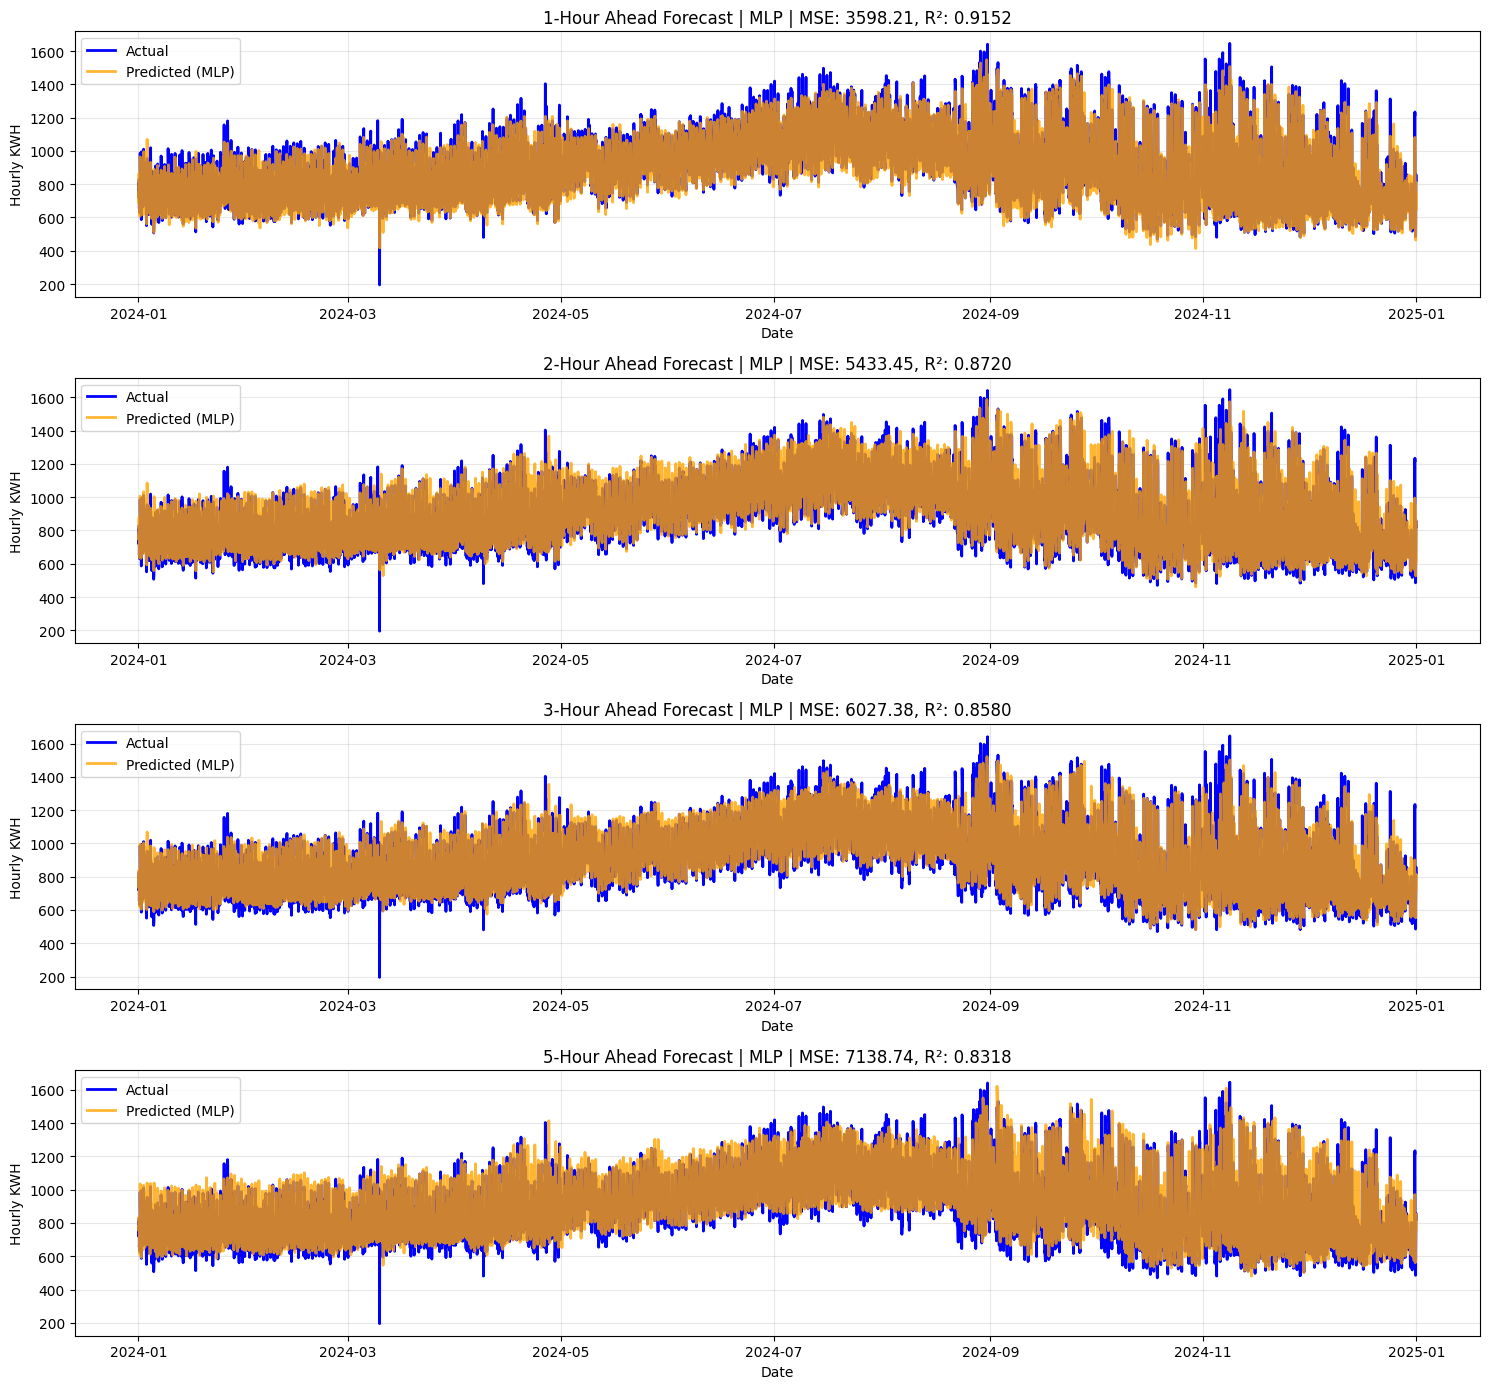

In [13]:
# Repeat multi-horizon results using only MLP

mlp_results = []
mlp_predictions_by_horizon = {}

for h in horizons:
    X_h, y_h = [], []
    for i in range(len(kwh_data) - n_hours - h + 1):
        X_h.append(kwh_data[i:i+n_hours])
        y_h.append(kwh_data[i+n_hours+h-1])

    X_h = np.array(X_h)
    y_h = np.array(y_h)

    split_idx_h = first_2024_idx - n_hours - (h - 1)
    X_train_h, X_test_h = X_h[:split_idx_h], X_h[split_idx_h:]
    y_train_h, y_test_h = y_h[:split_idx_h], y_h[split_idx_h:]
    test_dates_h = hourlyUsage.index[n_hours + (h - 1) + split_idx_h:]

    mlp_h = MLPRegressor(
        hidden_layer_sizes=(32, 16, 8),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42
)
    mlp_h.fit(X_train_h, y_train_h)
    y_pred_mlp_h = mlp_h.predict(X_test_h)

    mse_mlp_h = mean_squared_error(y_test_h, y_pred_mlp_h)
    r2_mlp_h = r2_score(y_test_h, y_pred_mlp_h)

    mlp_results.append({
        'Horizon_Hours': h,
        'Model': 'MLP',
        'MSE': mse_mlp_h,
        'R2': r2_mlp_h
    })

    mlp_predictions_by_horizon[h] = {
        'dates': test_dates_h,
        'y_test': y_test_h,
        'y_pred_mlp': y_pred_mlp_h
    }

mlp_results_df = pd.DataFrame(mlp_results).sort_values('Horizon_Hours')
print(mlp_results_df)

# Plot MLP predictions for each horizon
fig, axes = plt.subplots(len(horizons), 1, figsize=(15, 3.5 * len(horizons)), sharex=False)

for ax, h in zip(axes, horizons):
    d = mlp_predictions_by_horizon[h]
    row = mlp_results_df[mlp_results_df['Horizon_Hours'] == h].iloc[0]

    ax.plot(d['dates'], d['y_test'], label='Actual', color='blue', linewidth=2)
    ax.plot(d['dates'], d['y_pred_mlp'], label='Predicted (MLP)', color='orange', linewidth=2, alpha=0.8)
    ax.set_title(f'{h}-Hour Ahead Forecast | MLP | MSE: {row["MSE"]:.2f}, R²: {row["R2"]:.4f}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Hourly KWH')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()